In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.metrics import RocCurveDisplay, log_loss, roc_auc_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
eq = pd.read_csv("/content/drive/MyDrive/Earthquake_Project/earthquakes.tsv", sep="\t")
eq.shape

(6698, 39)

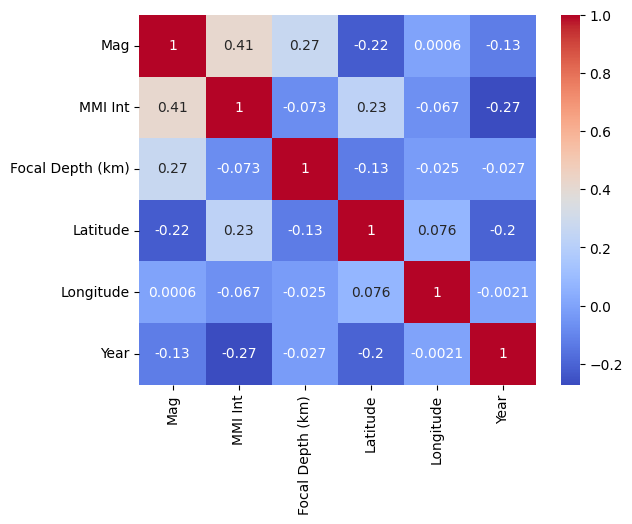

In [4]:
#correlation matrix
features = ["Mag","MMI Int","Focal Depth (km)","Latitude","Longitude","Year"]
corr_matrix = eq[features].corr()
sns.heatmap(corr_matrix, annot=True,cmap ="coolwarm")
plt.show()


This matrix showcases how this dataset is not the best for regression as the variables have little linear correlation. As a result, standard linear models are largly uninteresting or not useful at all. This weak linear relationship is a well-known characteristic of geophysical and geospatial datasets, which are inherently non-linear. While standard linear models fall short other models that do not rely on features being linearly correlated such as decision trees can prove useful to us.


This model is poor for regression as only mag and mmi int have a useful comparison

In [5]:
cols = ["Mag","MMI Int"]
lineareq = eq.dropna(subset=cols)
eq.shape

(6698, 39)

In [6]:
#linear regression using mag and Deaths
X= lineareq["Mag"].values.reshape(-1,1)
y=lineareq["MMI Int"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)
print(linear_model.coef_)
print(linear_model.intercept_)
#mean squared error
print("MSE:", np.mean((y_pred - y_test) ** 2))
#r-squared
print("R-Squared:",r2_score(y_test, y_pred))
#mean absolute error
print("MAE:", np.mean(np.abs(y_pred - y_test)))
#root mean squared error
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

[0.75296574]
2.8956118031960285
MSE: 2.5338429033936665
R-Squared: 0.18741777480605526
MAE: 1.2132681001977519


In [7]:
#linear regression with k-fold
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print(cross_val_score(linear_model, X, y, cv=kf, scoring="neg_mean_squared_error"))
print(cross_val_score(linear_model, X, y, cv=kf, scoring="r2"))

print("mean MSE score:", np.mean(cross_val_score(linear_model, X, y, cv=kf, scoring="neg_mean_squared_error")))
print("mean r2 score:", np.mean(cross_val_score(linear_model, X, y, cv=kf, scoring="r2")))

[-2.5338429  -2.79274634 -2.60598336 -2.33461255 -2.51736669]
[0.18741777 0.1847304  0.17899519 0.20163329 0.0839214 ]
mean MSE score: -2.556910369013554
mean r2 score: 0.1673396126310426


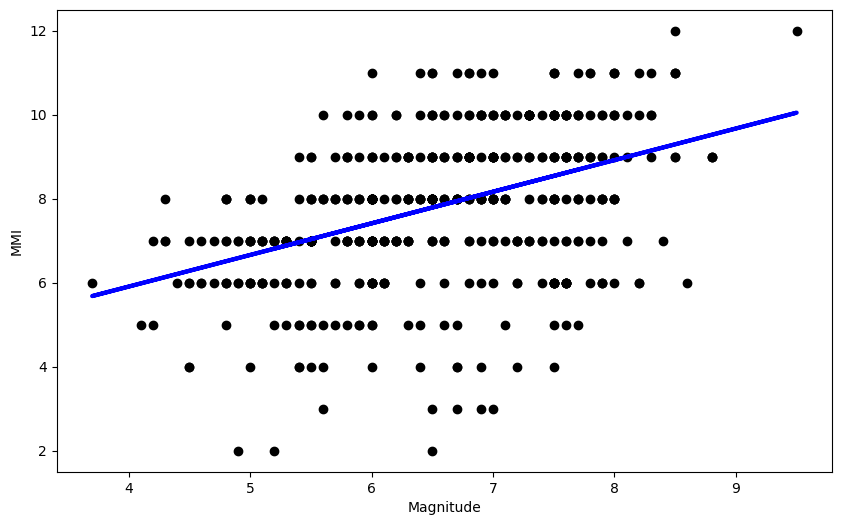

In [8]:
# map out linear regression model
plt.figure(figsize=(10,6))
plt.scatter(X_test, y_test, color='black')
plt.xlabel('Magnitude')
plt.ylabel('MMI')
plt.plot(X_test, y_pred, color='blue', linewidth=3)

These two features used on the simple linear regression model are the really only two features we can extract useful information from. Although it may not be interesting those two are the only two that are linearly correlated.

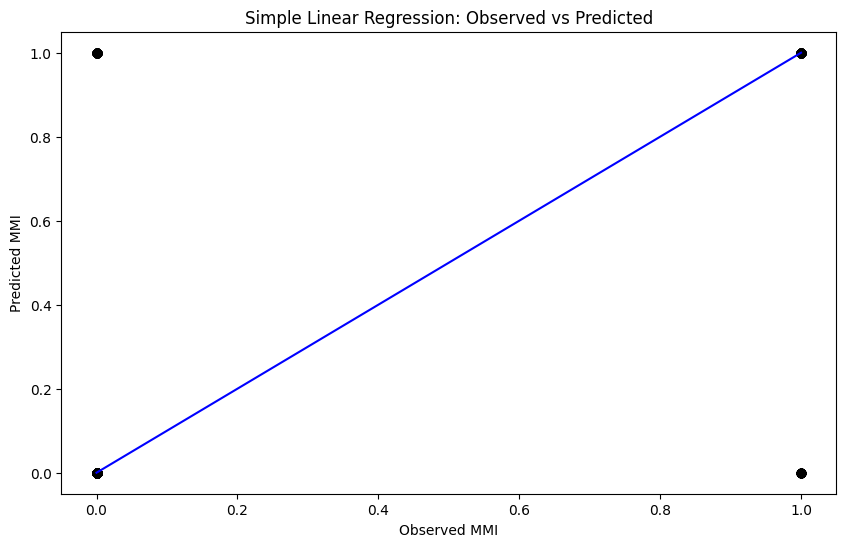

In [ ]:
#observed vs preficted values
plt.figure(figsize=(10,6))

plt.scatter(y_test, y_pred, color='black', alpha=0.6)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot([minimum, maximum], [minimum, maximum], color='blue')

plt.xlabel("Observed MMI")
plt.ylabel("Predicted MMI")
plt.title("Simple Linear Regression: Observed vs Predicted")
plt.show()

**Multi-linear Regression**

In [21]:
mult_eq = eq.dropna(subset=["Mag", "MMI Int", "Focal Depth (km)", "Latitude", "Longitude"])
mult_eq.shape

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

X = mult_eq[["Mag", "Focal Depth (km)", "Latitude", "Longitude"]].copy()
y = mult_eq["MMI Int"]

X["Focal Depth (km)"] = np.log1p(X["Focal Depth (km)"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

multmodel = LinearRegression()
multmodel.fit(X_train, y_train)

print(multmodel.coef_)
print(multmodel.intercept_)

y_pred = multmodel.predict(X_test)

print("MSE:", mean_squared_error(y_test, y_pred))
print("R-squared:", r2_score(y_test, y_pred))
print("MAE:", np.mean(np.abs(y_pred - y_test)))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))


[ 0.85321748 -0.20336186  0.4537192  -0.17428673]
7.41611234294161
MSE: 2.583302150622376
R-squared: 0.19825306262814668
MAE: 1.2632711642897858
RMSE: 1.607265426313394


In [10]:
#multi-regression with k-fold
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print(cross_val_score(multmodel, X, y, cv=kf, scoring="neg_mean_squared_error"))
print(cross_val_score(multmodel, X, y, cv=kf, scoring="r2"))

print("mean MSE score:", np.mean(cross_val_score(multmodel, X, y, cv=kf, scoring="neg_mean_squared_error")))
print("mean r2 score:", np.mean(cross_val_score(multmodel, X, y, cv=kf, scoring="r2")))

[-2.58330215 -2.62487622 -3.03083763 -2.60483516 -2.53381469]
[0.19825306 0.23791413 0.14787923 0.18733878 0.25498748]
mean MSE score: -2.6755331678993093
mean r2 score: 0.20527453690614514


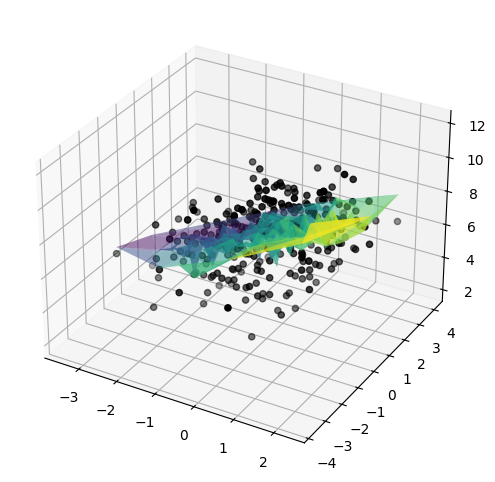

In [11]:
#map out multi linear regression
fig = plt.figure(figsize=(10,6))
#map prediction line
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_test[:,0], X_test[:,1], y_test, color='black')
ax.plot_trisurf(
    X_test[:, 0],
    X_test[:, 1],
    y_pred,
    cmap="viridis",
    alpha=0.5)

This model was the best we came together with and it has obvious issues specifically with r-squared and mse. The r-squared shows us that the model is only accounting for 20 percent of patterns in the earthquakes. For the MSE, because MMI Int is only on a 1-10 scale that means the models predicition is roughly 1.6 off. With the model being up to 1.6 off that can prove troublesome in the real world as differences in the mmi scale could cause damage to life and property.

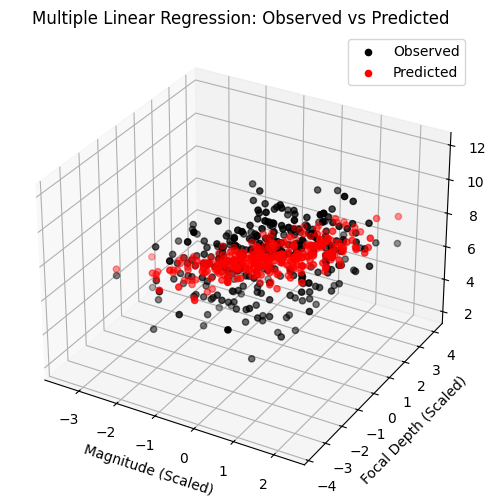

In [22]:
#map out multi linear regression
fig = plt.figure(figsize=(10,6))

ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X_test[:,0],
    X_test[:,1],
    y_test,
    color='black',
    label='Observed'
)

ax.scatter(
    X_test[:,0],
    X_test[:,1],
    y_pred,
    color='red',
    label='Predicted'
)

ax.set_xlabel('Magnitude (Scaled)')
ax.set_ylabel('Focal Depth (Scaled)')
ax.set_zlabel('MMI Int')

ax.set_title('Multiple Linear Regression: Observed vs Predicted')
ax.legend()

plt.show()

**Logistic Regression**

In [12]:
eq = eq.fillna({"Tsu": 0})
eq["Tsu"] = eq["Tsu"].apply(lambda x: 1 if x != 0 else 0)

eq = eq.dropna(subset=["Mag", "Focal Depth (km)", "Latitude", "Longitude"])

X = eq[["Mag", "Focal Depth (km)", "Latitude", "Longitude"]]
y = eq["Tsu"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_train, y_train)

print(clf.coef_)
print(clf.intercept_)

y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
#absolute and log loss
print("Absolute Loss:", np.mean(np.abs(y_pred - y_test)))
print("Log Loss:", np.mean(np.log(1 - y_pred)))

[[ 1.27389018 -0.00719505 -0.00690589  0.00157671]]
[-8.1153904]
Accuracy: 0.7338935574229691
Precision: 0.5204081632653061
Recall: 0.7574257425742574
F1 Score: 0.6169354838709677
Absolute Loss: 0.2661064425770308
Log Loss: -inf


/tmp/ipykernel_1345/4090300662.py:27: RuntimeWarning: divide by zero encountered in log
  print("Log Loss:", np.mean(np.log(1 - y_pred)))


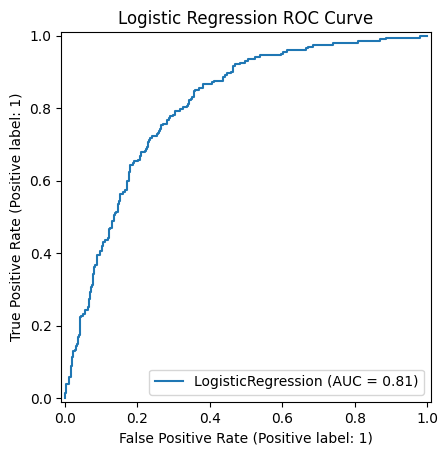

In [13]:
RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.title("Logistic Regression ROC Curve")
plt.show()

An AUC score of 0.81 means that our logistic regression model did a pretty good job distinguishing between earthquakes that caused tsunamis, and ones that didn't. Overall, the model shows strong proof that these chosen earthquake factors are useful when predicting weather or not an earthquake caused a tsunami.

In [18]:
# Logistic regression with k-fold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

scores = cross_val_score(logreg, X, y, cv=skf, scoring="accuracy")

print(f"Scores for each of the 5 folds: {scores}")
print(f"Average Accuracy: {scores.mean() * 100:.2f}%")
print(f"Score Variance (Std Dev): {scores.std() * 100:.2f}%")

Scores for each of the 5 folds: [0.75630252 0.71669004 0.71949509 0.73492286 0.73772791]
Average Accuracy: 73.30%
Score Variance (Std Dev): 1.43%


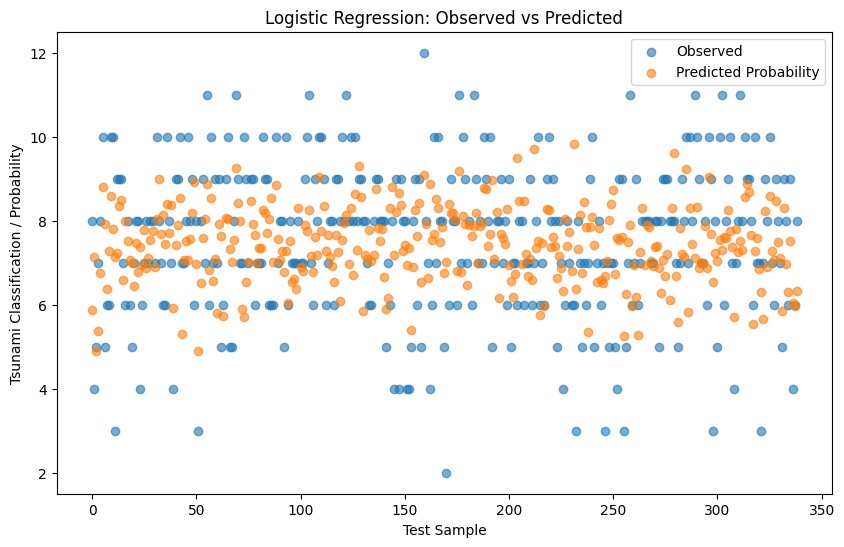

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    range(len(y_test)),
    y_test,
    label="Observed",
    alpha=0.6
)

plt.scatter(
    range(len(y_test)),
    y_pred,
    label="Predicted Probability",
    alpha=0.6
)


plt.xlabel("Test Sample")
plt.ylabel("Tsunami Classification / Probability")
plt.title("Logistic Regression: Observed vs Predicted")

plt.legend()
plt.show()

In [19]:
#bootstrap for logisitc regression
booteq = eq.dropna(subset=["Mag", "Focal Depth (km)", "Latitude", "Longitude","Tsu"])
booteq.shape

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#bootstap variables
n_interations = 1000
n_samples = len(booteq)
bootstrapped_coefs = []

rng = np.random.default_rng(seed=42)
for i in range(n_interations):
  bootstrapped_sample = booteq.sample(n=n_samples, replace=True,random_state=rng.integers(0, 100000))

  boot_X = bootstrapped_sample[["Mag", "Focal Depth (km)", "Latitude", "Longitude"]]
  boot_y = bootstrapped_sample["Tsu"]

  logreg = LogisticRegression(C=1e5,max_iter=1000)
  logreg.fit(boot_X, boot_y)
  bootstrapped_coefs.append(logreg.coef_)

boot_coefs_df = pd.DataFrame(np.squeeze(bootstrapped_coefs), columns=("Mag", "Focal Depth (km)", "Latitude", "Longitude"))

summary_stats = []
for col in ("Mag", "Focal Depth (km)", "Latitude", "Longitude"):
    coef_values = boot_coefs_df[col]

    boot_se = np.std(coef_values)

    ci_lower = np.percentile(coef_values, 2.5)
    ci_upper = np.percentile(coef_values, 97.5)

    summary_stats.append({
        'Feature': col,
        'Bootstrap SE': boot_se,
        '95% CI Lower': ci_lower,
        '95% CI Upper': ci_upper
    })

print(pd.DataFrame(summary_stats).to_string(index=False))

         Feature  Bootstrap SE  95% CI Lower  95% CI Upper
             Mag      0.053031      1.164971      1.371842
Focal Depth (km)      0.001460     -0.012217     -0.006453
        Latitude      0.001735     -0.010724     -0.003896
       Longitude      0.000457      0.000118      0.001914


Ths shows us the Mag is the driving factor when determining if a tsunami is likely or ot

In [28]:
#model comparison using adjusted r-squared

comparison_eq = mult_eq.dropna(subset=["Mag", "Focal Depth (km)", "Latitude", "Longitude", "MMI Int"])

X = comparison_eq[["Mag", "Focal Depth (km)", "Latitude", "Longitude"]].copy()
X["Focal Depth (km)"] = np.log1p(X["Focal Depth (km)"])
y = comparison_eq["MMI Int"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

simple_model = LinearRegression()
simple_model.fit(X_train[["Mag"]], y_train)

multiple_model = make_pipeline(StandardScaler(), LinearRegression())
multiple_model.fit(X_train, y_train)

simple_r2 = r2_score(y_test, simple_model.predict(X_test[["Mag"]]))
multiple_r2 = r2_score(y_test, multiple_model.predict(X_test))

n = len(y_test)

simple_adj_r2 = 1 - (1 - simple_r2) * (n - 1) / (n - 1 - 1)
multiple_adj_r2 = 1 - (1 - multiple_r2) * (n - 1) / (n - 4 - 1)

print("Simple Adjusted R-squared:", simple_adj_r2)
print("Multiple Adjusted R-squared:", multiple_adj_r2)

print("Better model:", "Multiple Regression" if multiple_adj_r2 > simple_adj_r2 else "Simple Regression")

Simple Adjusted R-squared: 0.15399549586957173
Multiple Adjusted R-squared: 0.18865130289914245
Better model: Multiple Regression
